# 03 · Clasificador de archivos por materia (clasificación)

**Objetivo:** dado el texto de un archivo académico, predecir a qué materia pertenece.

**Pipeline:** texto → limpieza (minúsculas, sin tildes, sin palabras vacías ni números) → TF-IDF con unigramas y bigramas → comparación de Regresión Logística, SVM lineal y Naive Bayes → métricas (accuracy, F1 macro, matriz de confusión).

> El corpus de este notebook es sintético: documentos de práctica armados con el vocabulario de cada materia del pénsum (`ml/corpus_sintetico.py`). Por eso las métricas son optimistas. Con archivos reales, que son más largos y comparten más vocabulario, se espera un resultado menor; el pipeline es el mismo.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", font_scale=0.95)
GRIS, OCRE, VERDE = "#4d4d4d", "#9a7b4f", "#5f7a6a"
plt.rcParams.update({"figure.dpi": 110, "axes.edgecolor": "#333333", "axes.titleweight": "bold"})
pd.set_option("display.precision", 3)

In [2]:
from ml import clasificador as cl
from ml.entrenar import RUTA_CORPUS, asegurar_datos

asegurar_datos()
corpus = pd.read_csv(RUTA_CORPUS)
print(f"{len(corpus)} documentos de {corpus['materia'].nunique()} materias")
print("Documentos por materia:", corpus["materia"].value_counts().unique())
print()
print(corpus.loc[0, "materia"], "→", corpus.loc[0, "texto"][:260], "...")

2640 documentos de 44 materias
Documentos por materia: [60]

Sistemas Operativos → Taller 4 Para la próxima clase, consulte llamadas al sistema. Repaso de cambio de contexto. Lea con atención cada punto antes de responder. Justifique todas sus respuestas. Se evaluará el manejo de paginación. Compare planificación de procesos con núcleo del s ...


## Comparación de modelos

In [3]:
evaluacion = cl.evaluar(corpus)
print("Mejor modelo por validación cruzada:", evaluacion["mejor"])
evaluacion["resultados"].set_index("modelo")

Mejor modelo por validación cruzada: Naive Bayes


,F1_macro_cv,accuracy,F1_macro
modelo,,,
Regresión logística,0.993,0.996,0.996
SVM lineal,0.992,0.996,0.996
Naive Bayes,0.994,0.994,0.994


## Métricas por materia

In [4]:
from sklearn.metrics import classification_report

modelo = evaluacion["modelos"][evaluacion["mejor"]]
X_prueba, y_prueba = evaluacion["X_prueba"], evaluacion["y_prueba"]
predicho = modelo.predict(X_prueba)
informe = pd.DataFrame(classification_report(y_prueba, predicho, output_dict=True)).T
print("Materias con menor F1:")
informe.drop(["accuracy", "macro avg", "weighted avg"]).sort_values("f1-score").head(8)[["precision", "recall", "f1-score", "support"]]

Materias con menor F1:


,precision,recall,f1-score,support
Lenguajes de Programación,1.000,0.917,0.957,12.0
Física y Laboratorio II,1.000,0.917,0.957,12.0
Proyecto Integrador Básico,1.000,0.917,0.957,12.0
Estructura de Datos,0.923,1.000,0.960,12.0
Proyecto Integrador Profesional,0.923,1.000,0.960,12.0
Física y Laboratorio I,0.923,1.000,0.960,12.0
Arquitectura de Computadores,1.000,1.000,1.000,12.0
Algoritmos y Programación I,1.000,1.000,1.000,12.0


## Matriz de confusión

Primero la de todo el pénsum y luego el detalle del semestre 7, que es el que el agente usa en la práctica: al clasificar solo considera las materias activas.

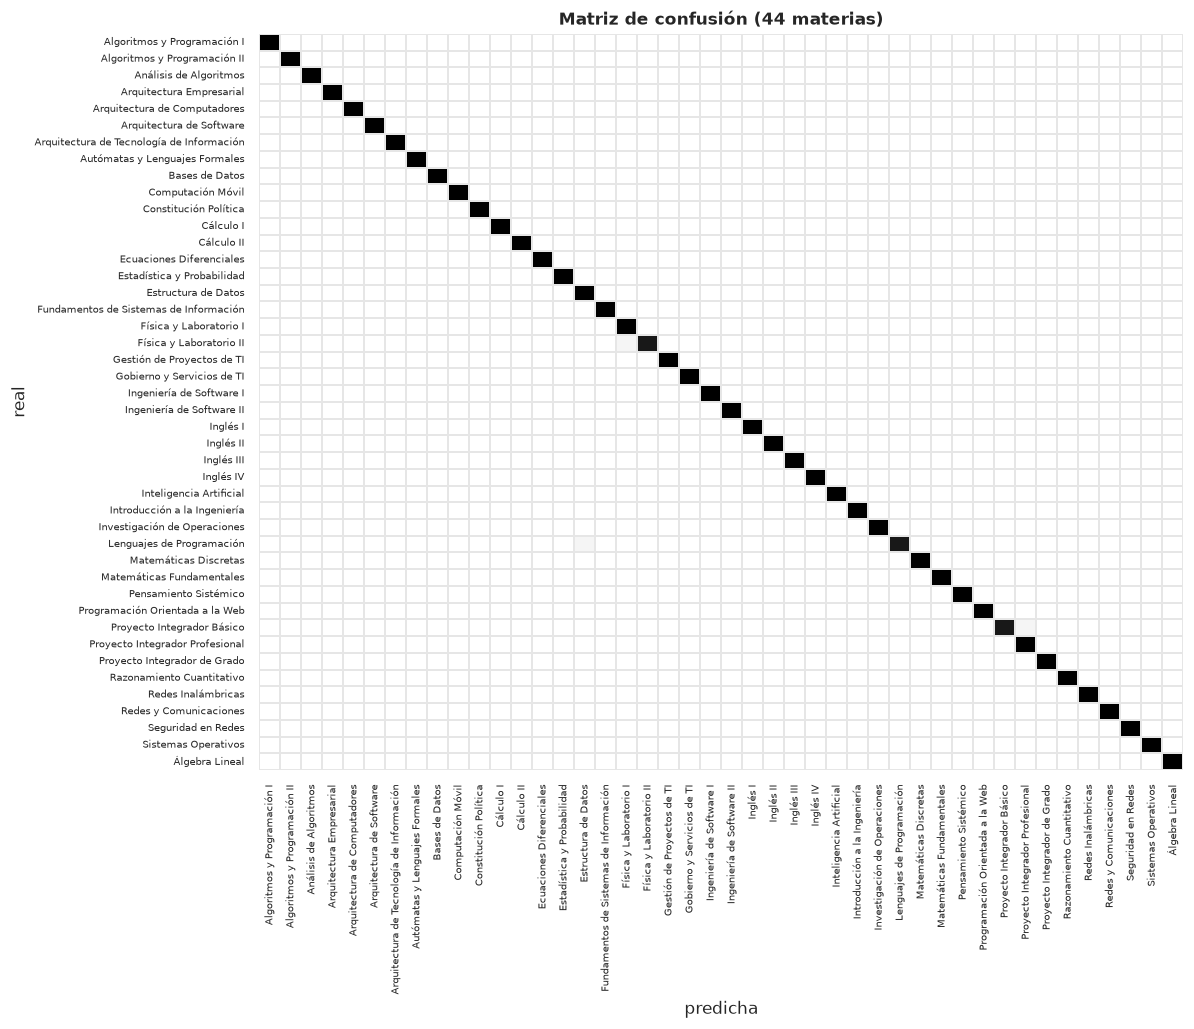

In [5]:
from sklearn.metrics import confusion_matrix

clases = list(modelo.classes_)
matriz = confusion_matrix(y_prueba, predicho, labels=clases)
fig, eje = plt.subplots(figsize=(11, 9.5))
sns.heatmap(matriz, cmap="Greys", cbar=False, xticklabels=clases, yticklabels=clases, linewidths=0.2, linecolor="#e6e6e6", ax=eje)
eje.set(title="Matriz de confusión (44 materias)", xlabel="predicha", ylabel="real")
eje.tick_params(labelsize=6.5)
plt.tight_layout()

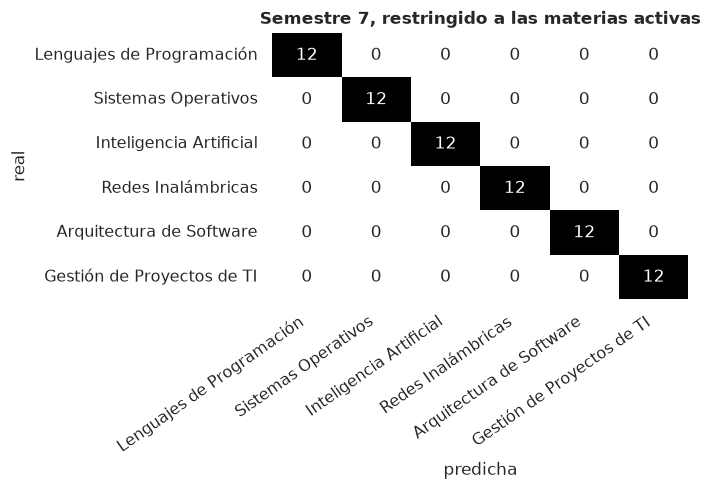

In [6]:
import json

pensum = json.loads((RAIZ / "data" / "pensum.json").read_text(encoding="utf-8"))["materias"]
septimo = [m["nombre"] for m in pensum if m["semestre"] == 7]
mascara = y_prueba.isin(septimo)
predicho_7 = [
    max(zip(septimo, [fila[clases.index(m)] for m in septimo]), key=lambda par: par[1])[0]
    for fila in modelo.predict_proba(X_prueba[mascara])
]
matriz_7 = confusion_matrix(y_prueba[mascara], predicho_7, labels=septimo)
fig, eje = plt.subplots(figsize=(6.5, 4.6))
sns.heatmap(matriz_7, annot=True, fmt="d", cmap="Greys", cbar=False, xticklabels=septimo, yticklabels=septimo, ax=eje)
eje.set(title="Semestre 7, restringido a las materias activas", xlabel="predicha", ylabel="real")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()

## Confusiones más frecuentes

In [7]:
pares = [
    (clases[i], clases[j], int(matriz[i, j]))
    for i in range(len(clases)) for j in range(len(clases)) if i != j and matriz[i, j] > 0
]
pd.DataFrame(sorted(pares, key=lambda p: -p[2]), columns=["real", "predicha", "casos"]).head(10)

,real,predicha,casos
0,Física y Laboratorio II,Física y Laboratorio I,1
1,Lenguajes de Programación,Estructura de Datos,1
2,Proyecto Integrador Básico,Proyecto Integrador Profesional,1


## Confianza y umbral

El agente mueve el archivo solo si la probabilidad supera el umbral (0,7 en `config.yaml`); si no, consulta al LLM o al usuario. La tabla muestra, para distintos umbrales, qué fracción de archivos se mueve sin preguntar y con qué acierto.

,se mueven solos,acierto en esos
umbral,,
0.5,0.996,0.994
0.6,0.985,0.998
0.7,0.973,0.998
0.8,0.970,0.998
0.9,0.941,1.000


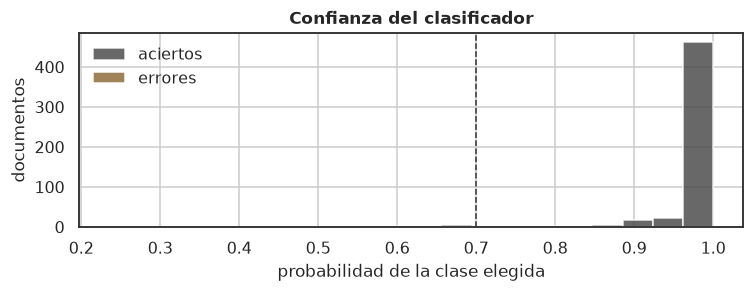

In [8]:
probabilidades = modelo.predict_proba(X_prueba)
confianza = probabilidades.max(axis=1)
acierto = predicho == y_prueba.to_numpy()
filas = []
for umbral in (0.5, 0.6, 0.7, 0.8, 0.9):
    automaticos = confianza >= umbral
    filas.append({"umbral": umbral, "se mueven solos": automaticos.mean(), "acierto en esos": acierto[automaticos].mean()})
display(pd.DataFrame(filas).set_index("umbral"))

fig, eje = plt.subplots(figsize=(7, 2.8))
eje.hist(confianza[acierto], bins=20, color=GRIS, alpha=0.85, label="aciertos")
eje.hist(confianza[~acierto], bins=20, color=OCRE, alpha=0.95, label="errores")
eje.axvline(0.7, color="#333333", linestyle="--", linewidth=1)
eje.set(title="Confianza del clasificador", xlabel="probabilidad de la clase elegida", ylabel="documentos")
eje.legend(frameon=False)
plt.tight_layout()

## Términos más informativos

Los términos con mayor peso TF-IDF medio en algunas materias del semestre 7. Sirve para verificar que el modelo se apoya en vocabulario propio de cada materia y no en ruido.

In [9]:
tfidf = modelo.named_steps["tfidf"]
terminos = np.array(tfidf.get_feature_names_out())
tabla = {}
for materia in ["Sistemas Operativos", "Inteligencia Artificial", "Redes Inalámbricas", "Arquitectura de Software"]:
    pesos = np.asarray(tfidf.transform(corpus.loc[corpus["materia"] == materia, "texto"]).mean(axis=0)).ravel()
    tabla[materia] = terminos[pesos.argsort()[::-1][:8]]
pd.DataFrame(tabla)

,Sistemas Operativos,Inteligencia Artificial,Redes Inalámbricas,Arquitectura de Software
0,procesos,supervisado,redes,arquitectura
1,sistema,aprendizaje supervisado,potencia,calidad
2,memoria,lenguaje,potencia transmision,modelo
3,paginacion,aprendizaje,transmision dbm,acoplamiento
4,planificacion procesos,busqueda heuristica,dbm,acoplamiento cohesion
5,planificacion,heuristica,transmision,cohesion
6,comunicacion procesos,gradiente,roaming,patrones diseno
7,algoritmos reemplazo,descenso,ofdm,patrones


## Comparación opcional con embeddings

Si `sentence-transformers` está instalado (`pip install sentence-transformers`), esta celda compara TF-IDF con embeddings de oraciones multilingües. No es una dependencia del proyecto porque descarga un modelo de varios cientos de megabytes.

In [10]:
try:
    from sentence_transformers import SentenceTransformer
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import f1_score
    from sklearn.model_selection import train_test_split

    codificador = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")
    vectores = codificador.encode(corpus["texto"].tolist(), show_progress_bar=False)
    X_e, X_p, y_e, y_p = train_test_split(vectores, corpus["materia"], test_size=0.2, stratify=corpus["materia"], random_state=42)
    f1 = f1_score(y_p, LogisticRegression(max_iter=2000).fit(X_e, y_e).predict(X_p), average="macro")
    print(f"F1 macro con embeddings: {f1:.3f}")
except ImportError:
    print("sentence-transformers no está instalado; se omite la comparación.")

sentence-transformers no está instalado; se omite la comparación.


## Modelo final

El mejor modelo se reentrena con todo el corpus y se guarda en `ml/modelos/`. Es el archivo que carga el skill `organizar_archivos`.

In [11]:
metricas = cl.entrenar_y_guardar(corpus, RAIZ / "ml" / "modelos")
metricas

{'modelo': 'Naive Bayes',
 'documentos': 2640,
 'materias': 44,
 'accuracy': 0.9943181818181818,
 'F1_macro': 0.994308300395257}

In [12]:
clasificador = cl.ClasificadorMaterias(RAIZ / "ml" / "modelos")
texto = "Laboratorio 2. Implemente un productor-consumidor con semáforos y memoria compartida usando fork."
print("Todo el pénsum:   ", [(m, round(p, 3)) for m, p in clasificador.clasificar(texto)[:3]])
print("Solo semestre 7:  ", [(m, round(p, 3)) for m, p in clasificador.clasificar(texto, septimo)[:3]])

Todo el pénsum:    [('Sistemas Operativos', 0.965), ('Estructura de Datos', 0.009), ('Análisis de Algoritmos', 0.002)]
Solo semestre 7:   [('Sistemas Operativos', 0.997), ('Lenguajes de Programación', 0.001), ('Inteligencia Artificial', 0.001)]
